# Random forest

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

In [63]:
dataset = pd.read_csv("../dataset/dataset_musique_region_transforme.csv")
dataset.head()

,variete_francaise,pop_rock,rap_hip_hop,classique,jazz,dance,electronique,metal,rnb,soul,reggae,musiques_du_monde,autres_genres,region,region_group,total_genres
0,1,0,0,0,1,0,0,0,0,1,0,0,0,Occitanie,SUD,3
1,0,1,0,0,1,0,0,0,0,0,0,1,0,Pays de la Loire,CENTRE,3
2,1,1,1,0,0,0,0,0,1,0,0,0,0,Hauts-de-France,NORD-OUEST,4
3,1,0,0,1,0,0,0,0,0,0,0,0,0,Provence-Alpes-Côte d'Azur,SUD,2
4,1,0,0,0,1,0,0,0,0,0,0,1,0,Auvergne-Rhône-Alpes,Auvergne-Rhône-Alpes,3


## Séparer les préférences et la région
- `X`  goûts musicaux 
- `y`  région à prédire

In [64]:
#X = dataset.drop(columns="region")
#y = dataset["region"]

#assert dataset.isna().sum().sum() == 0 #  valeur manquante dans le dataset 
#assert X.isin([0, 1]).all().all()

#print("Préférences :", X.shape)
#print("Régions :", y.nunique())

In [65]:
# Garder uniquement les 13 genres musicaux
X = dataset.drop(columns=["region", "region_group", "total_genres"])

# Région à prédire
y = dataset["region"]

# Vérifications
assert dataset.isna().sum().sum() == 0
assert X.isin([0, 1]).all().all()

print("Préférences :", X.shape)
print("Régions :", y.nunique())

Préférences : (1986, 13)
Régions : 12


## l’entraînement et le test
80 % des personnes pour apprendre et 20 % pour évaluer les prédictions
- `stratify=y` conserve des proportions de régions proches dans les deux groupes
- `random_state=42` permet de retrouver la même séparation

In [66]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Personnes pour apprendre :", len(X_train))
print("Personnes pour le test :", len(X_test))

Personnes pour apprendre : 1588
Personnes pour le test : 398


## Créer et entraîner
Une forêt combine les prédictions de plusieurs arbres
- `n_estimators=200` : on utilise 200 arbres
- `max_depth=8` : on limite la profondeur
- `random_state=42` : reproduire le calcul.

In [67]:
#surapprentissage 
modele = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42
)

#essai
#modele = RandomForestClassifier(
#    n_estimators=200,
#    max_depth=5,
#    min_samples_leaf=10,
#    random_state=42,
#    class_weight="balanced"
#)

#modele = RandomForestClassifier(
#   n_estimators=200,
#    max_depth=3,
#    min_samples_leaf=1,
#    random_state=42,
#)


modele.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

## Prédire les régions du test
Le modèle reçoit uniquement les préférences musicales des personnes du test

In [68]:
predictions = modele.predict(X_test)

resultats = pd.DataFrame({
    "Région réelle": y_test,
    "Région prédite": predictions
})
resultats["Bonne prédiction"] = resultats["Région réelle"] == resultats["Région prédite"]

resultats.head(10)

,Région réelle,Région prédite,Bonne prédiction
1195,Provence-Alpes-Côte d'Azur,Île-de-France,False
430,Île-de-France,Île-de-France,True
1364,Centre-Val de Loire,Île-de-France,False
1977,Occitanie,Île-de-France,False
772,Île-de-France,Île-de-France,True
627,Grand Est,Île-de-France,False
475,Occitanie,Île-de-France,False
807,Pays de la Loire,Hauts-de-France,False
1243,Nouvelle-Aquitaine,Île-de-France,False
797,Bourgogne-Franche-Comté,Île-de-France,False


## Mesurer les résultats
avce : 
- L’accuracy : proportion de personnes dont la région est bien prédite
- F1 :  entre 0 et 1, donne la même importance à chaque région (+ il est proche de 1, meilleures sont les perf)


Avant on avait : 

Accuracy entraînement	44,2 %	==> 22,5 %

Accuracy test	20,1 %	==> 21,4 %

Bonnes prédictions	80/398	==> 85/398

In [69]:
accuracy_train = modele.score(X_train, y_train)
accuracy_test = accuracy_score(y_test, predictions)
f1_macro = f1_score(y_test, predictions, average="macro", zero_division=0)

print("Accuracy entraînement :", round(accuracy_train * 100, 1), "%")
print("Accuracy test :", round(accuracy_test * 100, 1), "%")
print("F1 test :", round(f1_macro, 3))
print("Bonnes prédictions :", resultats["Bonne prédiction"].sum(), "sur", len(y_test))

Accuracy entraînement : 31.2 %
Accuracy test : 21.1 %
F1 test : 0.073
Bonnes prédictions : 84 sur 398


In [73]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

pred_baseline = baseline.predict(X_test)

print("Accuracy référence :", round(accuracy_score(y_test, pred_baseline) * 100, 1), "%")
print("Accuracy Random Forest :", round(accuracy_test * 100, 1), "%")

Accuracy référence : 20.4 %
Accuracy Random Forest : 21.1 %


## résultats par région
- précision :  mesure si les prédictions d’une région sont souvent justes
- rappel :  mesure combien de personnes de cette région sont retrouvées
- support ; est le nombre de personnes dans le test.

In [70]:
print(classification_report(y_test, predictions, digits=3, zero_division=0))

                            precision    recall  f1-score   support

      Auvergne-Rhône-Alpes      0.148     0.085     0.108        47
   Bourgogne-Franche-Comté      0.250     0.059     0.095        17
                  Bretagne      0.000     0.000     0.000        19
       Centre-Val de Loire      0.000     0.000     0.000        16
                 Grand Est      0.429     0.075     0.128        40
           Hauts-de-France      0.167     0.053     0.080        38
                 Normandie      0.000     0.000     0.000        18
        Nouvelle-Aquitaine      0.091     0.026     0.040        39
                 Occitanie      0.000     0.000     0.000        32
          Pays de la Loire      1.000     0.040     0.077        25
Provence-Alpes-Côte d'Azur      0.000     0.000     0.000        26
             Île-de-France      0.216     0.889     0.348        81

                  accuracy                          0.211       398
                 macro avg      0.192     0.10

## Visualiser les erreurs
La diagonale correspond aux bonnes réponses et les cases donnent des proportions dans chaque région réelle

1 : Auvergne-Rhône-Alpes
2 : Bourgogne-Franche-Comté
3 : Bretagne
4 : Centre-Val de Loire
5 : Grand Est
6 : Hauts-de-France
7 : Normandie
8 : Nouvelle-Aquitaine
9 : Occitanie
10 : Pays de la Loire
11 : Provence-Alpes-Côte d'Azur
12 : Île-de-France


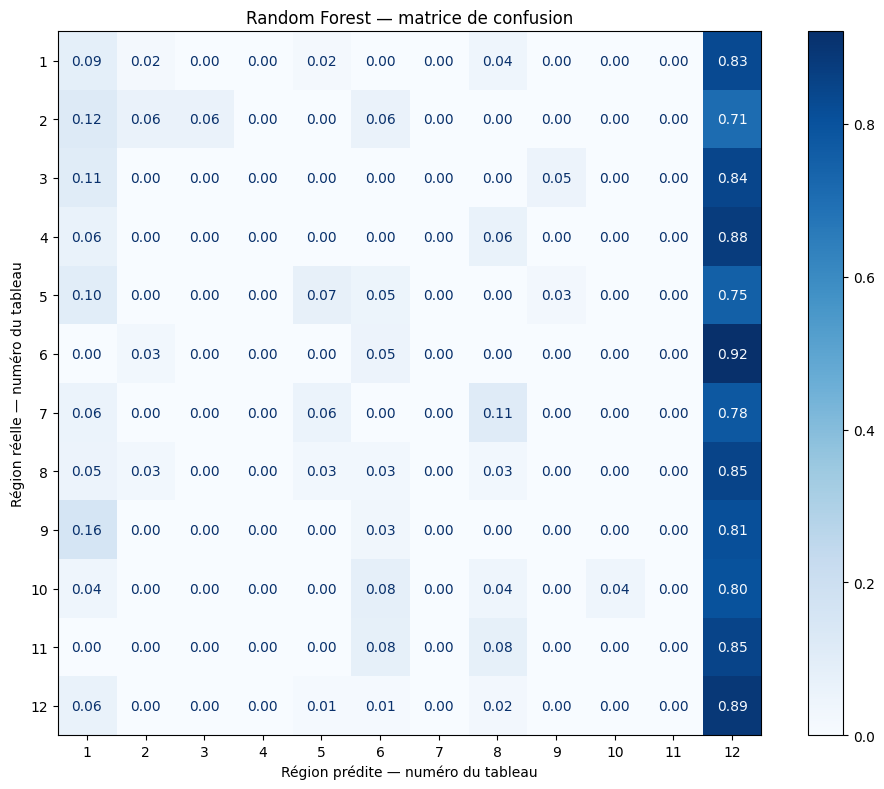

In [71]:
regions = sorted(y_train.unique())
numeros = list(range(1, len(regions) + 1))
for numero, region in zip(numeros, regions):
    print(f"{numero} : {region}")

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions,
    labels=regions,
    display_labels=numeros,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=ax
)
ax.set_xlabel("Région prédite — numéro du tableau")
ax.set_ylabel("Région réelle — numéro du tableau")
ax.set_title("Random Forest — matrice de confusion")
plt.tight_layout()
plt.show()

## Conclusion